<a href="https://colab.research.google.com/github/avaabarnes/A04-clustering/blob/main/notebook_(4).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts?
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Ava Barnes

**Date:** 10/12/2026


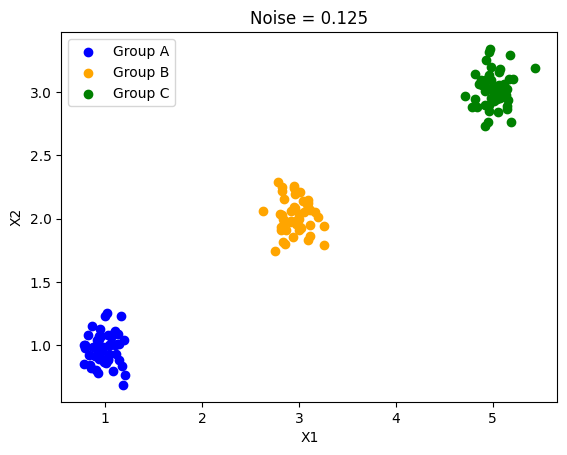

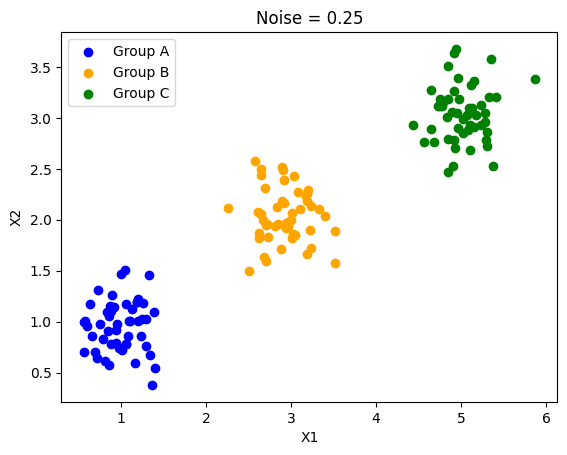

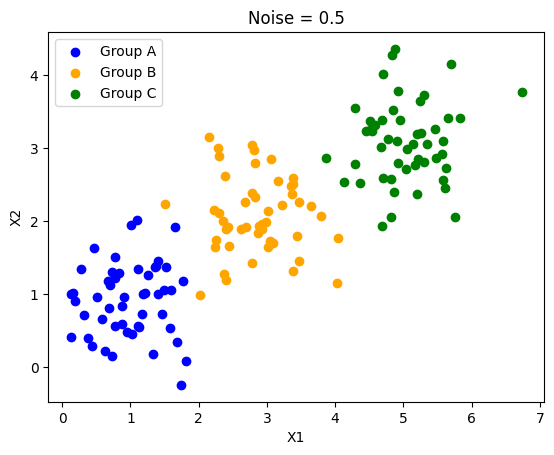

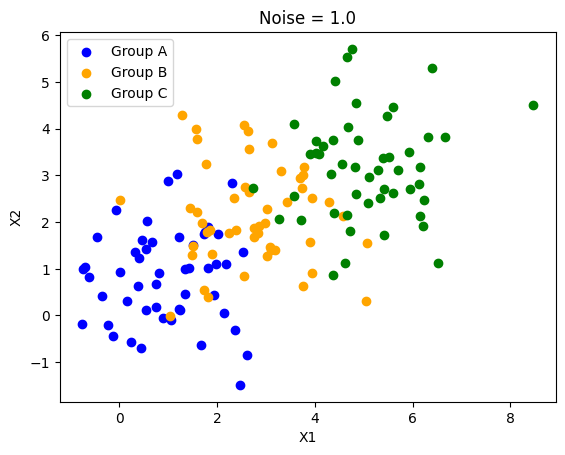

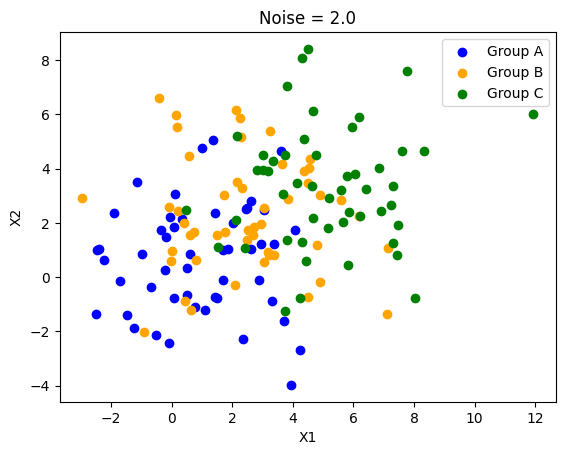

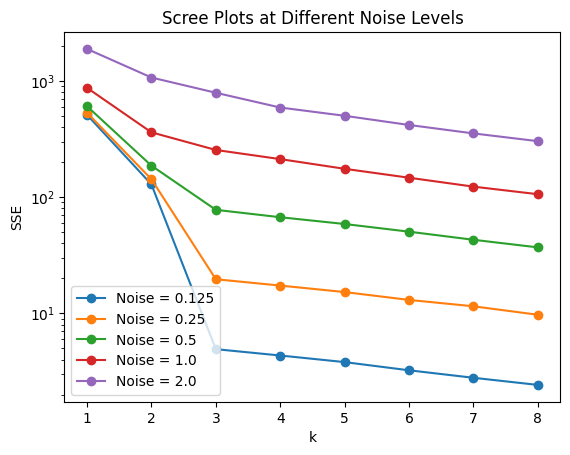

In [ ]:
# Question #1
import numpy as np
import pandas as pd

#running code from part 1
def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)


# creating scatterplots
import matplotlib.pyplot as plt


#0.125 noise scatterplot
  #group a
plt.scatter(df0_125[df0_125['group'] == 'a']['x1'],
            df0_125[df0_125['group'] == 'a']['x2'],
            color='blue', label='Group A')

  #group b
plt.scatter(df0_125[df0_125['group'] == 'b']['x1'],
            df0_125[df0_125['group'] == 'b']['x2'],
            color='orange', label='Group B')

  #group c
plt.scatter(df0_125[df0_125['group'] == 'c']['x1'],
            df0_125[df0_125['group'] == 'c']['x2'],
            color='green', label='Group C')

plt.xlabel('X1')
plt.ylabel('X2')
plt.title('Noise = 0.125')
plt.legend()
plt.show()
#plotting 0.125 noise

#0.25 scatterplot noise
  #group a
plt.scatter(df0_25[df0_25['group'] == 'a']['x1'],
            df0_25[df0_25['group'] == 'a']['x2'],
            color='blue', label='Group A')

  #group b
plt.scatter(df0_25[df0_25['group'] == 'b']['x1'],
            df0_25[df0_25['group'] == 'b']['x2'],
            color='orange', label='Group B')

  #group c
plt.scatter(df0_25[df0_25['group'] == 'c']['x1'],
            df0_25[df0_25['group'] == 'c']['x2'],
            color='green', label='Group C')

plt.xlabel('X1')
plt.ylabel('X2')
plt.title('Noise = 0.25')
plt.legend()
plt.show() #plotting 0.25 noise


#0.5 scatterplot noise
  #group a
plt.scatter(df0_5[df0_5['group'] == 'a']['x1'],
            df0_5[df0_5['group'] == 'a']['x2'],
            color='blue', label='Group A')

  #group b
plt.scatter(df0_5[df0_5['group'] == 'b']['x1'],
            df0_5[df0_5['group'] == 'b']['x2'],
            color='orange', label='Group B')

  #group c
plt.scatter(df0_5[df0_5['group'] == 'c']['x1'],
            df0_5[df0_5['group'] == 'c']['x2'],
            color='green', label='Group C')

plt.xlabel('X1')
plt.ylabel('X2')
plt.title('Noise = 0.5')
plt.legend()
plt.show() #plotting 0.5 noise


#1.0 scatterplot noise
  #group a
plt.scatter(df1_0[df1_0['group'] == 'a']['x1'],
            df1_0[df1_0['group'] == 'a']['x2'],
            color='blue', label='Group A')

  #group b
plt.scatter(df1_0[df1_0['group'] == 'b']['x1'],
            df1_0[df1_0['group'] == 'b']['x2'],
            color='orange', label='Group B')

  #group c
plt.scatter(df1_0[df1_0['group'] == 'c']['x1'],
            df1_0[df1_0['group'] == 'c']['x2'],
            color='green', label='Group C')

plt.xlabel('X1')
plt.ylabel('X2')
plt.title('Noise = 1.0')
plt.legend()
plt.show() #plotting 1.0 noise


#2.0 scatterplot noise
  #group a
plt.scatter(df2_0[df2_0['group'] == 'a']['x1'],
            df2_0[df2_0['group'] == 'a']['x2'],
            color='blue', label='Group A')

  #group b
plt.scatter(df2_0[df2_0['group'] == 'b']['x1'],
            df2_0[df2_0['group'] == 'b']['x2'],
            color='orange', label='Group B')

  #group c
plt.scatter(df2_0[df2_0['group'] == 'c']['x1'],
            df2_0[df2_0['group'] == 'c']['x2'],
            color='green', label='Group C')

plt.xlabel('X1')
plt.ylabel('X2')
plt.title('Noise = 2.0')
plt.legend()
plt.show() #plotting 2.0 noise


#part 3
from sklearn.cluster import KMeans

#scree plot
datasets = {0.125: df0_125, 0.25: df0_25, 0.5: df0_5, 1.0: df1_0, 2.0: df2_0}
ks = np.arange(1, 9)   # k = 1-8

for noise, d in datasets.items():
    X = d[['x1', 'x2']]
    SSE = [KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
           .fit(X).inertia_
           for k in ks]
    plt.plot(ks, SSE, 'o-', label=f'Noise = {noise}')

plt.xlabel('k')
plt.ylabel('SSE')
plt.title('Scree Plots at Different Noise Levels')
plt.yscale('log')   #SSE grows with noise, so a log axis keeps all five curves readable
plt.legend()
plt.show()



Question #1

Part 2) As the noise goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?

As the noise increase form 0.125 to 2.0 the visual distinctiveness decreases. at low noise levels, there are three clear group. However, as the noise increases these groups become more and more blended, spreading out and overlapping with each other. The cluster are clearly seperate through 0.5, begin to overlap at 1.0, and heavily overlap at 2.0

Part 3)  Describe how the level of noise affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a  𝑘 . (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)

As the noise level increase, the elbow in the scree plot becomes less clear which makes it harder to pick a k. At the noise of 0.125 and 0.25, there is a sharp elbow at k=3. At noise 0.5 the elbow at k=3 is still clear but the curve is less faly. At noise 1.0 the bend is much weaker so k-3 is possibly but not definite and at k=2.0 the cruve declines smoothly with no distinct elbow making it hard to select a k. Additionally, the vertical axis also differs across noise levels. The SSE values also increase as noise increases because the points are more spread out around their group centers. I plotted all five scree curves on the same graph to make their shapes easier to compare and used a logarithmic vertical axis because the SSE values vary considerably across noise levels.

Part4) 4. Explain the intuition of the elbow, using this numerical simulation as an example.

The elbow is the point of dimishing returns in k-means, where adding another cluster stops reducing SSE by much. SSE does not increases as k grows, instead it falls until it reaches 0 when every point is its own cluster, so we can't only choose the k with the lowest SSE. Instead, we look for the k after which adding another cluster stops reducing SSE by much.

In this simulation the true number of clusters is 3. When noise is low (at 0.125, 0.25), SSE falls sharply until k = 3 and then flattens, so the elbow is obvious. For 0.5, the SSE noticably falls until k=3 but is less clear than for 0.125 and 0.25. However, when the data is noisy, the data may not show you a clear k value. When noise is high (1.0 and 2.0), the groups overlap, so splitting at k = 3 doesn't reduce SSE much more than splitting at any other k. The elbow fades, and the plot no longer make it clear which k value is right.




(148, 7)
index                               int64
Year                                int64
Country                            object
Spending (2020 USD)               float64
Percent of GDP                    float64
Percent of Government Spending    float64
Spending per Capita               float64
dtype: object
0
                                count          mean           std  \
index                           148.0   2831.256757   1654.299355   
Year                            148.0   2020.000000      0.000000   
Spending (2020 USD)             148.0  13153.747670  68005.236120   
Percent of GDP                  148.0      0.019619      0.015033   
Percent of Government Spending  148.0      0.061510      0.046207   
Spending per Capita             148.0    268.264494    430.434878   

                                        min          25%          50%  \
index                             32.000000  1409.000000  2871.000000   
Year                            2020.000000  2020.0

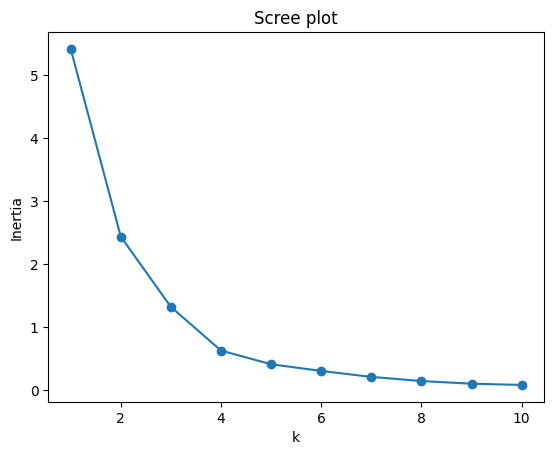

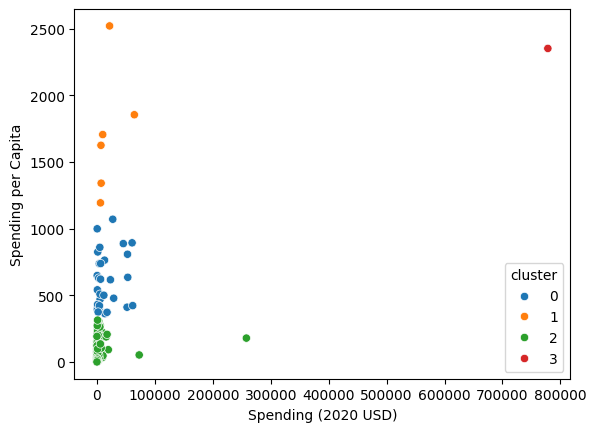

cluster                               0             1              2  \
Spending (2020 USD) count     30.000000      6.000000     111.000000   
                    mean   17077.591354  19443.362047    4859.185065   
                    std    20583.053357  22861.507114   25405.739131   
                    min      405.790494   6095.708713       8.622460   
                    25%     2294.039665   7023.251766     130.010211   
                    50%     5857.060906   8624.225729     382.464677   
                    75%    26296.001003  18857.070183    2297.032353   
                    max    61712.537169  64558.400000  257973.429834   
Spending per Capita count     30.000000      6.000000     111.000000   
                    mean     607.478618   1706.721916      80.061470   
                    std      206.928757    466.375705      83.501824   
                    min      362.467076   1193.598730       0.580129   
                    25%      422.208252   1412.083201      14.88

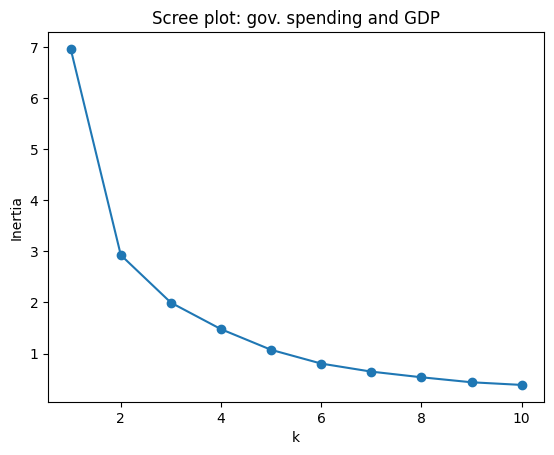

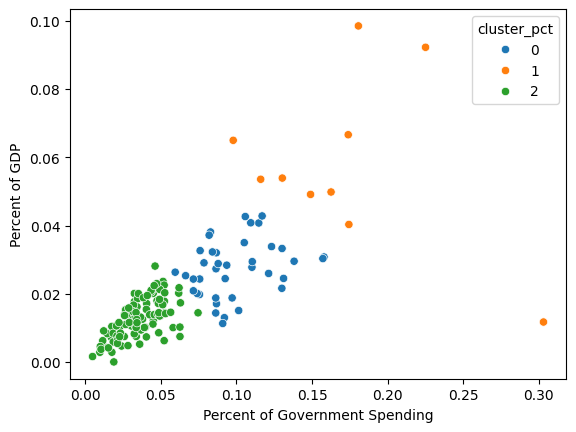

cluster_pct                                   0          1          2
Percent of Government Spending count  39.000000  10.000000  99.000000
                               mean    0.098683   0.171289   0.035777
                               std     0.024125   0.058725   0.014549
                               min     0.059520   0.097882   0.004896
                               25%     0.082430   0.135010   0.025921
                               50%     0.092044   0.168248   0.034261
                               75%     0.112633   0.179081   0.047402
                               max     0.157918   0.303027   0.074624
Percent of GDP                 count  39.000000  10.000000  99.000000
                               mean    0.027412   0.058071   0.012664
                               std     0.008191   0.024867   0.005681
                               min     0.011317   0.011742   0.000054
                               25%     0.021254   0.049297   0.008393
                    

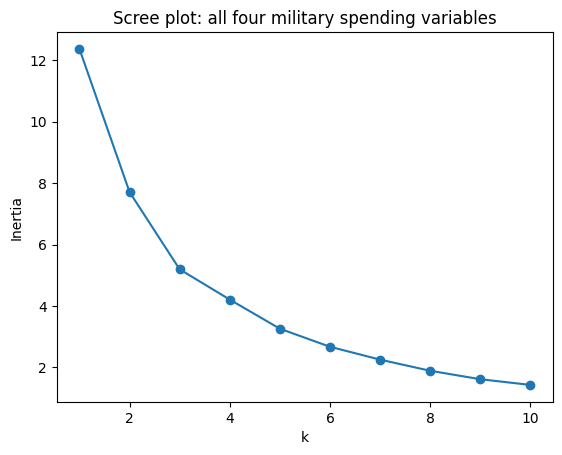

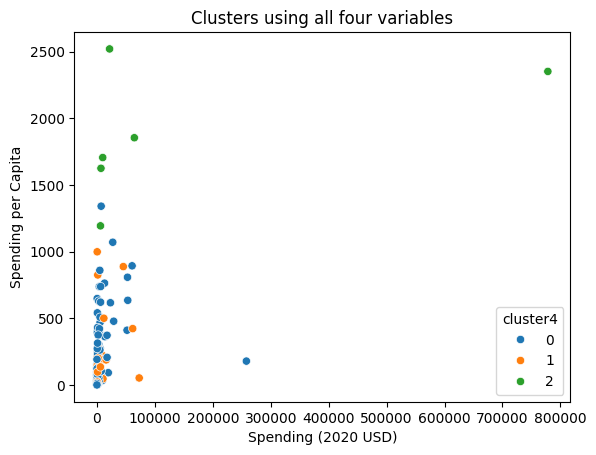

cluster4                                          0             1  \
Spending (2020 USD)            count     111.000000     31.000000   
                               mean     7086.472777   8786.086602   
                               std     26479.379918  17901.909108   
                               min         8.622460    162.373364   
                               25%       130.010211    467.787851   
                               50%       567.650747   1404.787234   
                               75%      3910.107493   7739.166193   
                               max    257973.429834  72937.064048   
Spending per Capita            count     111.000000     31.000000   
                               mean      196.926833    212.689100   
                               std       267.788506    257.841988   
                               min         0.580129     18.297119   
                               25%        14.880549     46.485917   
                               50%

In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
import seaborn as sns

mil = pd.read_csv('/content/SIPRI Military Expenditure Database.csv')
mil=mil[mil['Year'] == 2020].dropna().reset_index(drop=True)
#filtering the year to 2020 and dropping missing values

print(mil.shape)
print(mil.dtypes)
print(mil['Country'].duplicated().sum())   # output is 0
print(mil.describe().T) #no zero or negative values

s = 'Spending (2020 USD)'
p = 'Spending per Capita'
x = mil[[s, p]].apply(lambda s: (s - s.min()) / (s.max() - s.min()))
#max-min normalization on s and p

#creating scree plot
ks = range(1,11)
inertia = [KMeans(n_clusters=k, n_init=20, random_state=0).fit(x).inertia_ for k in ks]
plt.plot(ks, inertia, 'o-'); plt.xlabel('k'); plt.ylabel('Inertia'); plt.title('Scree plot')
plt.show() #shows elbow at 4, k=4

#fitting with the chosen k
mil['cluster'] = KMeans(n_clusters=4, n_init=20, random_state=0).fit_predict(x)

#creating scatterplot
sns.scatterplot(data=mil, x=s, y=p, hue='cluster', palette='tab10')
plt.show()

print(mil[[s, p]].groupby(mil['cluster']).describe().T) #describing graph
pd.set_option('display.max_colwidth', None)
print(mil.groupby('cluster')['Country'].apply(list)) #printing countries in each cluster

#repeating for percent of government spending and percent of GDP
gs = 'Percent of Government Spending'
gdp = 'Percent of GDP'
x3 = mil[[gs, gdp]].apply(lambda c: (c - c.min()) / (c.max() - c.min()))
#max-min normalization on gs and gdp

#creating scree plot
inertia3 = [KMeans(n_clusters=k, n_init=20, random_state=0).fit(x3).inertia_ for k in range(1,11)]
plt.plot(range(1,11), inertia3, 'o-'); plt.xlabel('k'); plt.ylabel('Inertia'); plt.title('Scree plot: gov. spending and GDP')
plt.show() #shows elbow at 3, k=3

#fitting with the chosen k
mil['cluster_pct'] = KMeans(n_clusters=3, n_init=20, random_state=0).fit_predict(x3)

#creating scatterplot
sns.scatterplot(data=mil, x=gs, y=gdp, hue='cluster_pct', palette='tab10')
plt.show()

print(mil[[gs, gdp]].groupby(mil['cluster_pct']).describe().T)
print(mil.groupby('cluster_pct')['Country'].apply(list))

#part 4 - using all 4 variables

s = 'Spending (2020 USD)'
p = 'Spending per Capita'
gs = 'Percent of Government Spending'
gdp = 'Percent of GDP'

# Min-max normalize all four variables
variables = [s, p, gs, gdp]
x4 = mil[variables].apply(
    lambda c: (c - c.min()) / (c.max() - c.min())
)

# Create scree plot
ks = range(1, 11)

inertia4 = [KMeans(n_clusters=k, n_init=20, random_state=0).fit(x4).inertia_ for k in ks]

plt.plot(ks, inertia4, 'o-')
plt.xlabel('k')
plt.ylabel('Inertia')
plt.title('Scree plot: all four military spending variables')
plt.show()

# Choose k based on the elbow in the scree plot
# Replace 3 with the k supported by your plot
mil['cluster4'] = KMeans(n_clusters=3, n_init=20, random_state=0).fit_predict(x4)

# Scatterplot: total spending vs. spending per capita
sns.scatterplot(data=mil, x=s, y=p,hue='cluster4', palette='tab10')
plt.title('Clusters using all four variables')
plt.show()

# Describe all four variables by cluster
print(mil.groupby('cluster4')[variables].describe().T)

# Print countries in each cluster
print(mil.groupby('cluster4')['Country'].apply(list))

# Print the number of countries in each cluster
print(mil.groupby('cluster4').size())


Question 2---

Part 1) No further cleaning is required after filtering the rows to only 2020 onwards and dropping the missing values. The data types are all correct, numbers are integers and words are strings.

Part 2)  Compute a describe table conditional on cluster membership (i.e. .groupby(cluster).describe()). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?

The table shows the four clusters are separated mainly by spending per capita. Cluster 0 has 30 countries, averaging 607 dollars per capita. Cluster 1 has 6 countries, averaging 1,707 dollars per capita. Cluster 2 has 111 countries, averaging 80 dollars per capita. Cluster 3 has one country, averaging 2,352 dollars per capita. These spending per capita ranges of clusters barely overlap.

The US is alone in cluster 3. The US spent 778B dollars in 2020, roughly three times as much as the next highest spending country in cluster 2 at 258B dollars. The US per capita spending is one of the highest in the data set at 2,351 dollars. This makes the US an outlier in the total spending, sitting high on spending per capita and spending in 2020.  

One pattern I noticed about cluster membership is that cluster 1 is made up of small or mid-sized countries that spend a lot per person. These countries include Kuwait, Israel, Singapore. Another pattern I noticed was that cluster 0 is most wealthy European NATO allies like Germany and France but also includes Russia and Taiwan. Cluster 2 is the rest of the world, including China and India. These countries have little spedning person around 80 dollars. Lastly, cluster 3 is only the US, which sits as a outlier on the graph.


Part 3) How do your results compare to part 2?

The results of part 3 different from part 2. First off, the scree plot for the two variables shows an elbow at k=3, so I used 3 clusters instead of 4 (part 2). The cluster split countries into low, medium, and high military burden. The low cluster, cluster 2, has 99 countries, average 3.6 percent of government spending and 1.3 percent of GDP. The medium cluster, cluster 0, has 39 countries and averages 9.9 percent of government spending and 2.74 percent of GDP. The high cluster, cluster 1, has 17.1 percent government spending and 5.8 percent GDP.

The clusters represent different levels of military spending relative to the economy. Cluster 2 is the low-burden group, with 99 countries averaging 3.6% of government spending and 1.3% of GDP. Cluster 0 is the medium-burden group, with 39 countries averaging 9.9% of government spending and 2.74% of GDP. Cluster 1 is the high-burden group, with 10 countries averaging 17.1% of government spending and 5.8% of GDP.

The United States is no longer an outlier in this two-variable clustering. It belongs to the medium-burden cluster alongside 38 other countries. The cluster sizes are also different from Part 2: 99, 39, and 10 countries, compared with 111, 30, 6, and 1. These results show that countries with very different military budgets can have similar levels of military spending relative to their economies.


Part 4) How do your results compare to the previous two parts?

The results of part 4 show another way to group the countries based upon military spending. Part 2 the clusters were based on total military spedning and spending per capita which reflected both overall size of the country's military budget and how much it spend per person. Part 3 the clusters were based on military spending as a percentage of government spending and GDP which reflected the relative burden of the military spending on the country's economy. In part 4, the results show three clusters containing 111, 31, and 6 countries. The United States is grouped with Israel, Kuwait, Oman, Saudi Arabia, and Singapore in the six-country cluster. This cluster has relatively high average spending per capita and high military spending as a percentage of government spending and GDP. The United States still stands out because of its exceptionally high total military spending, but it no longer forms its own cluster. Overall, using all four variables provides a more complete picture of military spending by considering both the absolute amount countries spend and the relative burden on their economies.

Part 5) Yes, the K-means algorithm helped identify patterns in military spending that were not immediately obvious from looking at the data alone. It grouped countries with similar spending characteristics and showed that countries can differ in both the absolute amount they spend on their militaries and the relative burden of that spending on their economies. The results also highlighted the United States as an outlier in total military spending when using the first two variables. Overall, k-means was useful for organizing the data into groups and identifying similarities and differences between countries. However, the results depend on the variables selected and the number of clusters chosen.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]